In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import confusion_matrix, classification_report

USE_TRANSFER_LEARNING = True      # True = MobileNetV2 (recommended), False = custom CNN
DATA_DIR = 'Dataset'              # change if your folder is elsewhere
CLASS_NAMES = ['Cat', 'Buffalo', 'Elephant', 'Rhino', 'Zebra']
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS = 30

print("Working dir:", os.getcwd())
print("Dataset folders:", os.listdir(DATA_DIR))

print(tf.config.list_physical_devices('GPU'))

I0000 00:00:1790629604.838228   25114 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790629604.876051   25114 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1790629605.827075   25114 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Working dir: /home/chhay/Documents/AI/CNN-on-the-prediction-of-image
Dataset folders: ['validation', 'train', 'test']
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [15]:
if USE_TRANSFER_LEARNING:
    from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
    common = dict(preprocessing_function=preprocess_input)   # scales to [-1, 1]
else:
    common = dict(rescale=1. / 255)                          # scales to [0, 1]

train_gen = ImageDataGenerator(
    rotation_range=15,
    zoom_range=0.15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    brightness_range=(0.8, 1.2),
    horizontal_flip=True,
    **common,
)
val_gen = ImageDataGenerator(**common)
test_gen = ImageDataGenerator(**common)

options = dict(target_size=IMG_SIZE, classes=CLASS_NAMES,
               batch_size=BATCH_SIZE, class_mode='categorical')

train_dataset = train_gen.flow_from_directory(f'{DATA_DIR}/train/', shuffle=True, **options)
validation_dataset = val_gen.flow_from_directory(f'{DATA_DIR}/validation/', shuffle=False, **options)
test_dataset = test_gen.flow_from_directory(f'{DATA_DIR}/test/', shuffle=False, **options)

print(train_dataset.class_indices)

Found 2999 images belonging to 5 classes.
Found 500 images belonging to 5 classes.
Found 500 images belonging to 5 classes.
{'Cat': 0, 'Buffalo': 1, 'Elephant': 2, 'Rhino': 3, 'Zebra': 4}


In [3]:
x, y = next(train_dataset)
print("Batch:", x.shape, "min:", x.min(), "max:", x.max())
print("Labels sample:", y[:3])

Batch: (16, 224, 224, 3) min: -1.0 max: 1.0
Labels sample: [[1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 1. 0. 0. 0.]]


In [4]:
def build_transfer_model():
    base = tf.keras.applications.MobileNetV2(
        input_shape=IMG_SIZE + (3,), include_top=False, weights='imagenet')
    base.trainable = False
    inputs = layers.Input(shape=IMG_SIZE + (3,))
    x = base(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(len(CLASS_NAMES), activation='softmax')(x)
    return models.Model(inputs, outputs), base


def build_custom_cnn():
    model = models.Sequential([
        layers.Input(shape=IMG_SIZE + (3,)),

        layers.Conv2D(32, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.Conv2D(64, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.Conv2D(128, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.Conv2D(256, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.GlobalAveragePooling2D(),

        layers.Dense(256, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(len(CLASS_NAMES), activation='softmax'),
    ])
    return model, None


model, base = build_transfer_model() if USE_TRANSFER_LEARNING else build_custom_cnn()

model.compile(
    optimizer=optimizers.Adam(1e-3 if USE_TRANSFER_LEARNING else 1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy'],
)
model.summary()

I0000 00:00:1790629663.124613   25114 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1212 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [5]:
cbs = [
    callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1),
]

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS,
    callbacks=cbs,
)

Epoch 1/30


I0000 00:00:1790629674.238988   25114 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1790629676.313160   25279 service.cc:153] XLA service 0x717794033100 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1790629676.313189   25279 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3050 Laptop GPU, Compute Capability 8.6 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.26.0)
I0000 00:00:1790629676.382189   25279 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1790629676.872695   25279 cuda_dnn.cc:461] Loaded cuDNN version 92600
I0000 00:00:1790629676.920038   25279 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_7794__.122


  3/188 ━━━━━━━━━━━━━━━━━━━━ 12s 68ms/step - accuracy: 0.1667 - loss: 1.9301     

I0000 00:00:1790629686.235526   25279 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


 21/188 ━━━━━━━━━━━━━━━━━━━━ 16s 101ms/step - accuracy: 0.5149 - loss: 1.2149

I0000 00:00:1790629688.835101   25277 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_7794__.122


188/188 ━━━━━━━━━━━━━━━━━━━━ 47s 185ms/step - accuracy: 0.9010 - loss: 0.2967 - val_accuracy: 0.9880 - val_loss: 0.0620 - learning_rate: 0.0010
Epoch 2/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 21s 109ms/step - accuracy: 0.9703 - loss: 0.0912 - val_accuracy: 0.9900 - val_loss: 0.0411 - learning_rate: 0.0010
Epoch 3/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 20s 104ms/step - accuracy: 0.9760 - loss: 0.0721 - val_accuracy: 0.9880 - val_loss: 0.0425 - learning_rate: 0.0010
Epoch 4/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 19s 101ms/step - accuracy: 0.9770 - loss: 0.0678 - val_accuracy: 0.9940 - val_loss: 0.0287 - learning_rate: 0.0010
Epoch 5/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 19s 101ms/step - accuracy: 0.9800 - loss: 0.0652 - val_accuracy: 0.9940 - val_loss: 0.0336 - learning_rate: 0.0010
Epoch 6/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.9823 - loss: 0.0517
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
188/188 ━━━━━━━━━━━━━━━━━━━━ 18s 98ms/step - accuracy: 0.9823 - loss: 0.0

In [7]:
if USE_TRANSFER_LEARNING:
    base.trainable = True
    for layer in base.layers[:-30]:          # keep early layers frozen
        layer.trainable = False
    for layer in base.layers:                # keep BatchNorm frozen for stability
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

    model.compile(
        optimizer=optimizers.Adam(1e-5),
        loss='categorical_crossentropy',
        metrics=['accuracy'],
    )
    history_ft = model.fit(
        train_dataset,
        validation_data=validation_dataset,
        epochs=10,
        callbacks=[callbacks.EarlyStopping(monitor='val_loss', patience=3,
                                           restore_best_weights=True)],
    )
    for key, values in history_ft.history.items():
        history.history.setdefault(key, []).extend(values)

Epoch 1/10


I0000 00:00:1790630623.691269   25279 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_63918__.122


183/188 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.9921 - loss: 0.0201

I0000 00:00:1790630642.611101   25278 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_63918__.122


188/188 ━━━━━━━━━━━━━━━━━━━━ 28s 123ms/step - accuracy: 0.9923 - loss: 0.0199 - val_accuracy: 0.9960 - val_loss: 0.0115
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - accuracy: 0.9947 - loss: 0.0145 - val_accuracy: 0.9940 - val_loss: 0.0145
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 20s 109ms/step - accuracy: 0.9967 - loss: 0.0095 - val_accuracy: 0.9960 - val_loss: 0.0091
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 19s 102ms/step - accuracy: 0.9960 - loss: 0.0118 - val_accuracy: 0.9960 - val_loss: 0.0096
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 20s 105ms/step - accuracy: 0.9987 - loss: 0.0057 - val_accuracy: 0.9940 - val_loss: 0.0147
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 19s 103ms/step - accuracy: 0.9977 - loss: 0.0067 - val_accuracy: 0.9980 - val_loss: 0.0057
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 20s 107ms/step - accuracy: 0.9987 - loss: 0.0056 - val_accuracy: 0.9960 - val_loss: 0.0128
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 21s 110ms/step - accuracy: 0.9963 - loss: 0.0089 - val

## 7. Training curves

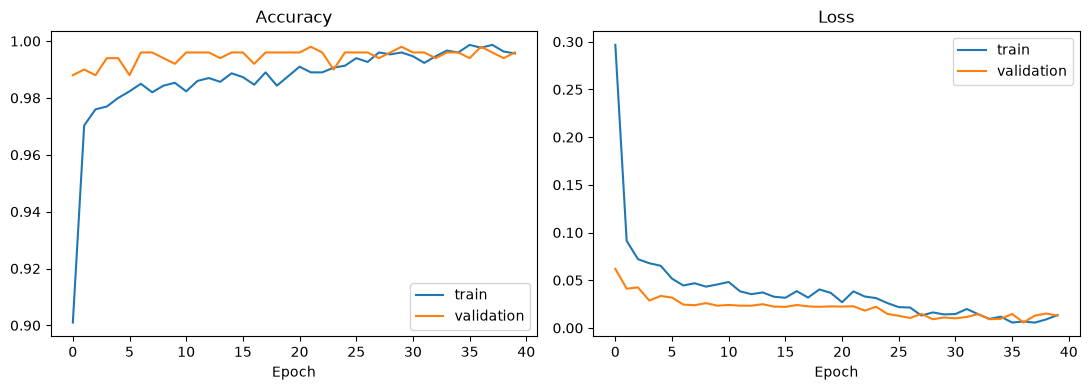

In [12]:
plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='validation')
plt.title('Accuracy'); plt.xlabel('Epoch'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='validation')
plt.title('Loss'); plt.xlabel('Epoch'); plt.legend()
plt.tight_layout()
plt.show()

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9980 - loss: 0.0093
Test accuracy: 0.998
32/32 ━━━━━━━━━━━━━━━━━━━━ 5s 87ms/step
              precision    recall  f1-score   support

         Cat       1.00      1.00      1.00       100
     Buffalo       0.99      1.00      1.00       100
    Elephant       1.00      0.99      0.99       100
       Rhino       1.00      1.00      1.00       100
       Zebra       1.00      1.00      1.00       100

    accuracy                           1.00       500
   macro avg       1.00      1.00      1.00       500
weighted avg       1.00      1.00      1.00       500



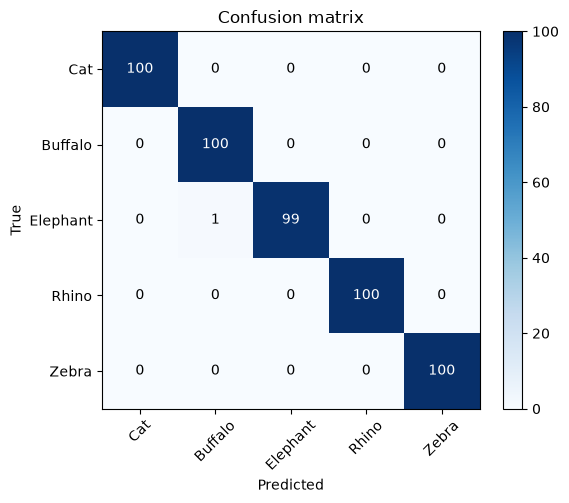

In [16]:
test_loss, test_acc = model.evaluate(test_dataset)
print(f"Test accuracy: {test_acc:.3f}")

test_dataset.reset()
y_pred = np.argmax(model.predict(test_dataset), axis=1)
y_true = test_dataset.classes               # valid because shuffle=False

print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap='Blues')
plt.title('Confusion matrix')
plt.xticks(range(len(CLASS_NAMES)), CLASS_NAMES, rotation=45)
plt.yticks(range(len(CLASS_NAMES)), CLASS_NAMES)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha='center', va='center',
                 color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.xlabel('Predicted'); plt.ylabel('True')
plt.colorbar()
plt.tight_layout()
plt.show()

## 9. Save the model

In [17]:
model.save('animal_classifier.keras')

## 10. Predict a single image

In [19]:
from tensorflow.keras.preprocessing import image

def predict_image(path):
    img = image.load_img(path, target_size=IMG_SIZE)
    arr = image.img_to_array(img)
    if USE_TRANSFER_LEARNING:
        arr = preprocess_input(arr)
    else:
        arr = arr / 255.0
    arr = np.expand_dims(arr, axis=0)
    probs = model.predict(arr)[0]
    idx = int(np.argmax(probs))
    print(f"{CLASS_NAMES[idx]} ({probs[idx] * 100:.1f}%)")
    plt.imshow(img); plt.axis('off'); plt.show()

# predict_image('Dataset/test/Zebra/example.jpg')